In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Rutas base relativas a CURVATURA_CAFE/integrantes
BASE_DIR = Path("..").resolve()
DATOS_DIR = BASE_DIR / "datos"
RESULTADOS_DIR = BASE_DIR / "resultados_finales"
INFORME_DIR = BASE_DIR / "informe"

RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)
INFORME_DIR.mkdir(parents=True, exist_ok=True)

archivo_derivadas = DATOS_DIR / "derivadas_tueste_cafe.csv"
archivo_base = DATOS_DIR / "datos_tueste_cafe.csv"

def calcular_derivadas_df(df_base: pd.DataFrame) -> pd.DataFrame:
    """Calcula T'(t) y T''(t) por diferencias finitas si aún no existe el CSV del Integrante 2."""
    df = df_base.copy().sort_values("t_min").reset_index(drop=True)
    t = df["t_min"].to_numpy(dtype=float)
    T = df["T_C"].to_numpy(dtype=float)
    dt = float(np.median(np.diff(t)))

    dT = np.zeros_like(T)
    d2T = np.zeros_like(T)

    # Primera derivada T'(t) [°C/min]
    dT[0] = (-3*T[0] + 4*T[1] - T[2]) / (2 * dt)          # Adelante O(h^2)
    dT[1:-1] = (T[2:] - T[:-2]) / (2 * dt)                 # Centrada O(h^2)
    dT[-1] = (3*T[-1] - 4*T[-2] + T[-3]) / (2 * dt)        # Atrás O(h^2)

    # Segunda derivada T''(t) [°C/min^2]
    d2T[0] = (2*T[0] - 5*T[1] + 4*T[2] - T[3]) / (dt**2)   # Adelante O(h^2)
    d2T[1:-1] = (T[2:] - 2*T[1:-1] + T[:-2]) / (dt**2)     # Centrada O(h^2)
    d2T[-1] = (2*T[-1] - 5*T[-2] + 4*T[-3] - T[-4]) / (dt**2)  # Atrás O(h^2)

    df["dT_dt_C_min"] = dT
    df["d2T_dt2_C_min2"] = d2T
    return df

if archivo_derivadas.exists():
    df = pd.read_csv(archivo_derivadas)
    print(f"Cargado archivo del Integrante 2: {archivo_derivadas}")
else:
    df_base = pd.read_csv(archivo_base)
    df = calcular_derivadas_df(df_base)
    print(f"Archivo de derivadas no encontrado; calculado desde: {archivo_base}")

# Normalizar nombres de columnas por si el Integrante 2 usó nombres ligeramente distintos
col_t = next((c for c in df.columns if "t" in c.lower() and "min" in c.lower()), df.columns[0])
col_T = next((c for c in df.columns if c.lower().startswith("t_") or "temp" in c.lower()), df.columns[1])
col_d1 = next((c for c in df.columns if "d1" in c.lower() or "ror" in c.lower() or "dT" in c or "prima" in c.lower() or "1" in c), None)
col_d2 = next((c for c in df.columns if "d2" in c.lower() or "d2T" in c or "segunda" in c.lower() or "2" in c), None)

if col_d1 is None or col_d2 is None:
    df = calcular_derivadas_df(pd.read_csv(archivo_base))
    col_t, col_T, col_d1, col_d2 = "t_min", "T_C", "dT_dt_C_min", "d2T_dt2_C_min2"

df = df.rename(columns={col_t: "t_min", col_T: "T_C", col_d1: "RoR_C_min", col_d2: "d2T_dt2_C_min2"})
df.head(12)

Cargado archivo del Integrante 2: C:\Users\ASUS\Desktop\METODOS\biosensor-ambiental\CURVATURA_CAFE\datos\derivadas_tueste_cafe.csv


,Etapa,t_min,T_C,RoR_C_min,d2T_dt2_C_min2
0,Carga del café verde,0.0,100.0,10.0,6.0
1,Inicio del secado,1.0,110.0,13.0,6.0
2,Secado intermedio,2.0,126.0,17.5,3.0
3,Secado avanzado,3.0,145.0,14.5,-9.0
4,Amarillamiento,4.0,155.0,10.0,0.0
5,Transición a Maillard,5.0,165.0,10.0,0.0
6,Inicio de Maillard,6.0,175.0,8.5,-3.0
7,Maillard avanzado,7.0,182.0,7.0,0.0
8,Desarrollo de color,8.0,189.0,7.0,0.0
9,Primer crack,9.0,196.0,6.5,-1.0


In [15]:
t = df["t_min"].to_numpy(dtype=float)
T = df["T_C"].to_numpy(dtype=float)
dT = df["RoR_C_min"].to_numpy(dtype=float)
d2T = df["d2T_dt2_C_min2"].to_numpy(dtype=float)

# Curvatura geométrica K(t) [1/min] (asumiendo t en min y T en °C en el plano (t, T))
K = np.abs(d2T) / np.power(1.0 + np.power(dT, 2), 1.5)
df["K_t"] = K

# Detección de cambios de signo en T''(t) (posibles puntos de inflexión)
signos = np.sign(d2T)
inflexiones = []
for i in range(len(df) - 1):
    if signos[i] == 0:
        inflexiones.append((i, t[i], T[i], "T''(t) = 0 exacto en nodo"))
    elif signos[i] * signos[i + 1] < 0:
        # Interpolación lineal del instante donde T''(t) cruza por cero
        t_infl = t[i] - d2T[i] * (t[i + 1] - t[i]) / (d2T[i + 1] - d2T[i])
        T_infl = np.interp(t_infl, t, T)
        inflexiones.append((i, round(float(t_infl), 3), round(float(T_infl), 2), f"Cambio de signo entre t={t[i]} y t={t[i+1]} min"))

# Clasificación orientativa de etapas térmicas del tueste
def clasificar_etapa(row):
    if row["t_min"] <= 4.0 and row["T_C"] < 150.0:
        return "Secado / Deshidratación (endotérmico)"
    elif row["t_min"] < 9.0:
        return "Maillard / Transición térmica"
    elif abs(row["t_min"] - 9.0) < 1e-6:
        return "Primer crack (exotérmico incipiente)"
    else:
        return "Desarrollo post-primer crack (exotérmico)"

df["regimen_termico"] = df.apply(clasificar_etapa, axis=1)

# Guardar tabla final consolidada
ruta_salida_csv = RESULTADOS_DIR / "curvatura_tueste_cafe_final.csv"
df.to_csv(ruta_salida_csv, index=False)

print("Tabla consolidada guardada en:", ruta_salida_csv)
print("\nPuntos de inflexión / cruces de T''(t):")
for item in inflexiones:
    print(" ", item)

idx_k_max = int(np.argmax(K))
print(f"\nMáxima curvatura K(t): K = {K[idx_k_max]:.6f} en t = {t[idx_k_max]:.1f} min (T = {T[idx_k_max]:.1f} °C)")
df[["t_min", "T_C", "RoR_C_min", "d2T_dt2_C_min2", "K_t", "regimen_termico"]]

Tabla consolidada guardada en: C:\Users\ASUS\Desktop\METODOS\biosensor-ambiental\CURVATURA_CAFE\resultados_finales\curvatura_tueste_cafe_final.csv

Puntos de inflexión / cruces de T''(t):
  (2, 2.25, 130.75, 'Cambio de signo entre t=2.0 y t=3.0 min')
  (4, np.float64(4.0), np.float64(155.0), "T''(t) = 0 exacto en nodo")
  (5, np.float64(5.0), np.float64(165.0), "T''(t) = 0 exacto en nodo")
  (7, np.float64(7.0), np.float64(182.0), "T''(t) = 0 exacto en nodo")
  (8, np.float64(8.0), np.float64(189.0), "T''(t) = 0 exacto en nodo")

Máxima curvatura K(t): K = 0.094868 en t = 11.0 min (T = 205.0 °C)


,t_min,T_C,RoR_C_min,d2T_dt2_C_min2,K_t,regimen_termico
0,0.0,100.0,10.0,6.0,0.005911,Secado / Deshidratación (endotérmico)
1,1.0,110.0,13.0,6.0,0.002707,Secado / Deshidratación (endotérmico)
2,2.0,126.0,17.5,3.0,0.000557,Secado / Deshidratación (endotérmico)
3,3.0,145.0,14.5,-9.0,0.002931,Secado / Deshidratación (endotérmico)
4,4.0,155.0,10.0,0.0,0.000000,Maillard / Transición térmica
5,5.0,165.0,10.0,0.0,0.000000,Maillard / Transición térmica
6,6.0,175.0,8.5,-3.0,0.004785,Maillard / Transición térmica
7,7.0,182.0,7.0,0.0,0.000000,Maillard / Transición térmica
8,8.0,189.0,7.0,0.0,0.000000,Maillard / Transición térmica
9,9.0,196.0,6.5,-1.0,0.003516,Primer crack (exotérmico incipiente)


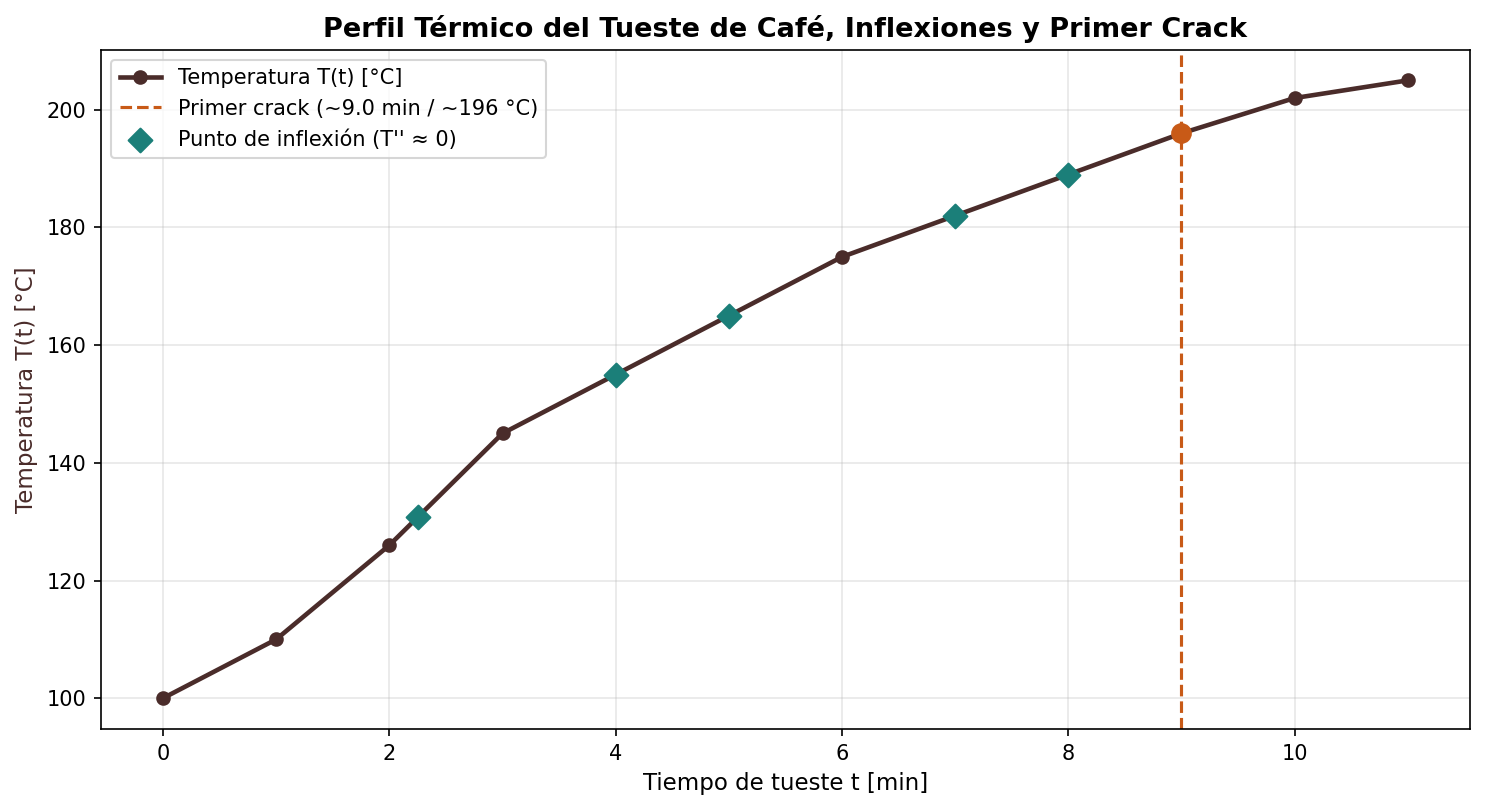

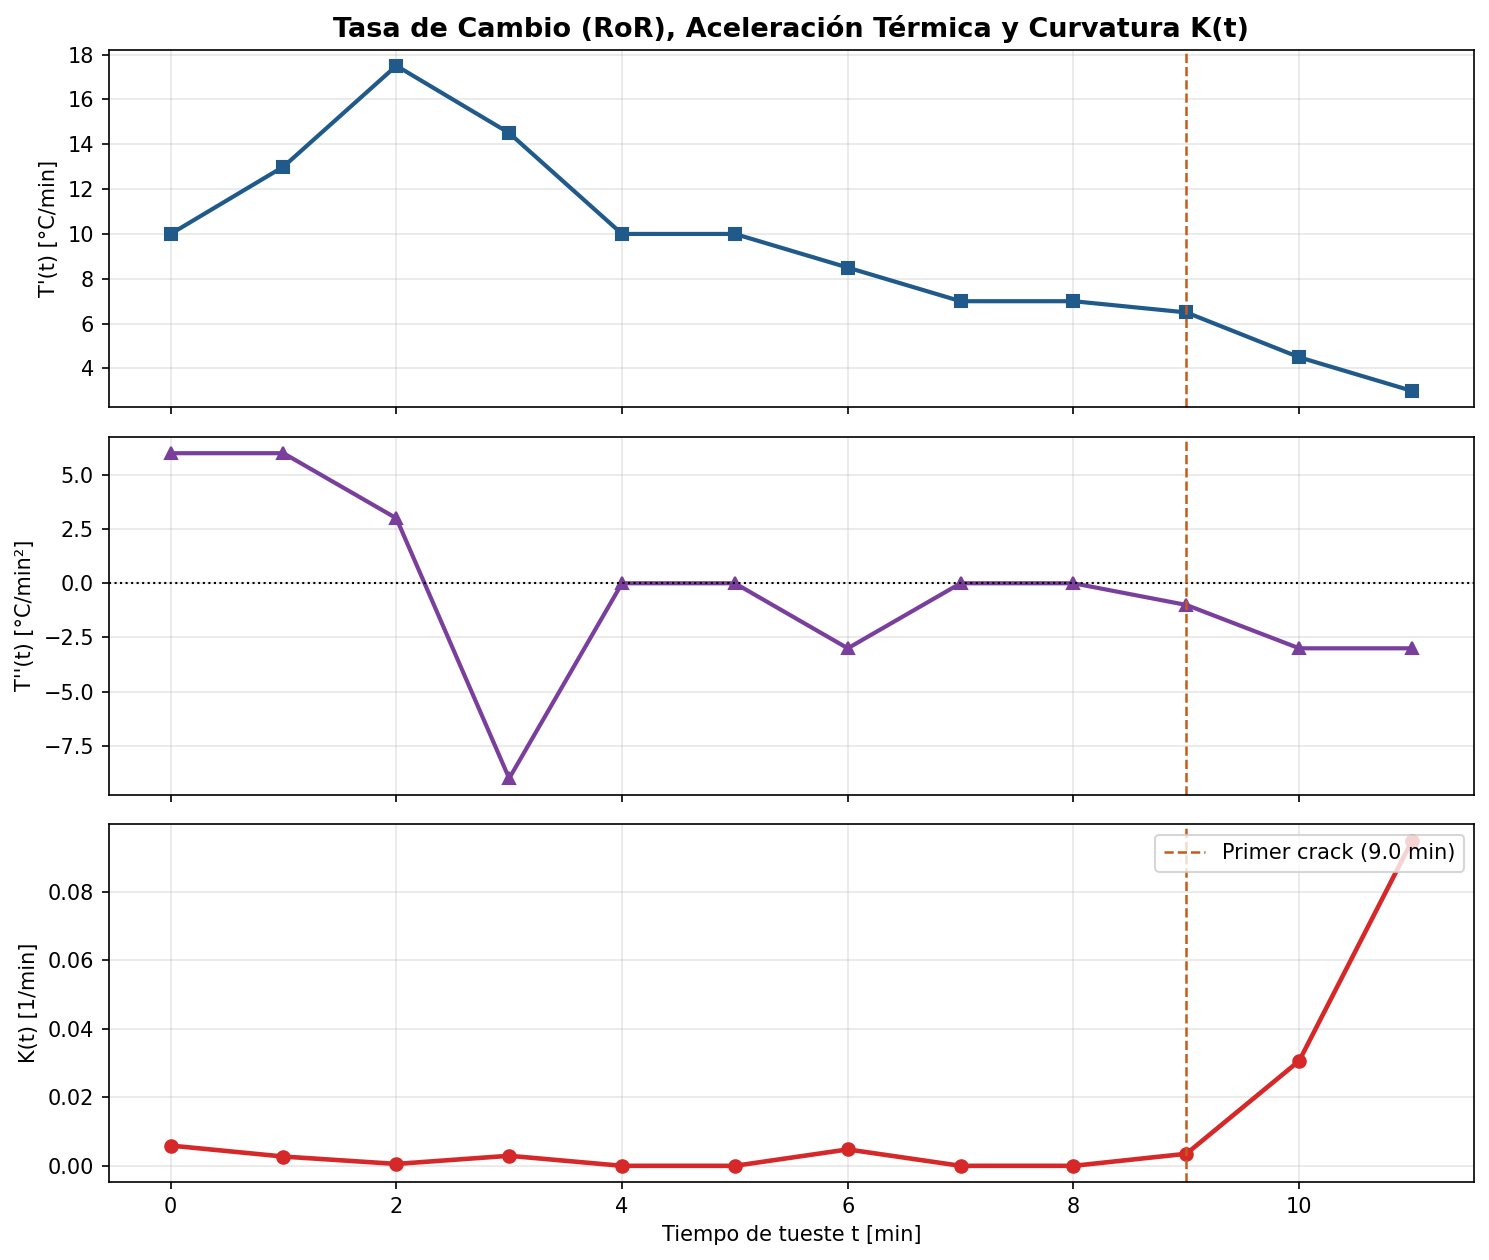

In [16]:
plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Figura 1: Curva de tueste T(t), inflexiones y Primer Crack ---
fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax1.plot(t, T, marker="o", linewidth=2.2, color="#4A2C2A", label="Temperatura T(t) [°C]")
ax1.axvline(9.0, color="#C85A17", linestyle="--", linewidth=1.5, label="Primer crack (~9.0 min / ~196 °C)")
ax1.scatter([9.0], [np.interp(9.0, t, T)], color="#C85A17", s=80, zorder=5)

for _, t_inf, T_inf, _ in inflexiones:
    ax1.scatter([t_inf], [T_inf], color="#1B7F79", marker="D", s=65, zorder=6,
                label="Punto de inflexión (T'' ≈ 0)" if t_inf == inflexiones[0][1] else "")

ax1.set_title("Perfil Térmico del Tueste de Café, Inflexiones y Primer Crack", fontsize=13, fontweight="bold")
ax1.set_xlabel("Tiempo de tueste t [min]", fontsize=11)
ax1.set_ylabel("Temperatura T(t) [°C]", fontsize=11, color="#4A2C2A")
ax1.legend(loc="upper left")
fig.tight_layout()
fig.savefig(RESULTADOS_DIR / "perfil_termico_inflexiones.png", dpi=300)
plt.show()

# --- Figura 2: Derivadas T'(t), T''(t) y Curvatura Geométrica K(t) ---
fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)

axes[0].plot(t, dT, marker="s", color="#1F5A8A", linewidth=2)
axes[0].axvline(9.0, color="#C85A17", linestyle="--", linewidth=1.2)
axes[0].set_ylabel("T'(t) [°C/min]")
axes[0].set_title("Tasa de Cambio (RoR), Aceleración Térmica y Curvatura K(t)", fontsize=13, fontweight="bold")

axes[1].plot(t, d2T, marker="^", color="#7A3E9D", linewidth=2)
axes[1].axhline(0.0, color="black", linewidth=1.0, linestyle=":")
axes[1].axvline(9.0, color="#C85A17", linestyle="--", linewidth=1.2)
axes[1].set_ylabel("T''(t) [°C/min²]")

axes[2].plot(t, K, marker="o", color="#D62828", linewidth=2.2)
axes[2].axvline(9.0, color="#C85A17", linestyle="--", linewidth=1.2, label="Primer crack (9.0 min)")
axes[2].set_ylabel("K(t) [1/min]")
axes[2].set_xlabel("Tiempo de tueste t [min]")
axes[2].legend(loc="upper right")

fig.tight_layout()
fig.savefig(RESULTADOS_DIR / "derivadas_y_curvatura_Kt.png", dpi=300)
plt.show()

In [19]:
import ipywidgets as widgets
from IPython.display import display, clear_output

minuto_input = widgets.FloatText(
    value=2.0,
    description="Minuto:",
    step=1.0,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="180px")
)

salida_tabla = widgets.Output()

def actualizar_tabla(change):
    minuto = change["new"]
    with salida_tabla:
        clear_output(wait=True)
        t_min = float(df["t_min"].min())
        t_max = float(df["t_min"].max())

        if minuto is None or minuto < t_min or minuto > t_max:
            print(f"Escribe un minuto entre {t_min} y {t_max}.")
            return

        exacto = df[np.isclose(df["t_min"], minuto, atol=1e-6)]

        if not exacto.empty:
            fila = exacto.iloc[0]
            tabla = pd.DataFrame({
                "Variable": [
                    "Tiempo (min)",
                    "Temperatura T (°C)",
                    "RoR T'(t) (°C/min)",
                    "2da Derivada T''(t) (°C/min²)",
                    "Curvatura K(t) (1/min)",
                    "Régimen térmico"
                ],
                "Valor": [
                    fila["t_min"],
                    round(float(fila["T_C"]), 4),
                    round(float(fila["RoR_C_min"]), 4),
                    round(float(fila["d2T_dt2_C_min2"]), 4),
                    round(float(fila["K_t"]), 6),
                    fila["regimen_termico"]
                ]
            })
        else:
            T_val = float(np.interp(minuto, df["t_min"], df["T_C"]))
            dT_val = float(np.interp(minuto, df["t_min"], df["RoR_C_min"]))
            d2T_val = float(np.interp(minuto, df["t_min"], df["d2T_dt2_C_min2"]))
            K_val = abs(d2T_val) / ((1.0 + dT_val**2) ** 1.5)
            tabla = pd.DataFrame({
                "Variable": [
                    "Tiempo (min)",
                    "Temperatura T (°C)",
                    "RoR T'(t) (°C/min)",
                    "2da Derivada T''(t) (°C/min²)",
                    "Curvatura K(t) (1/min)",
                    "Estado"
                ],
                "Valor": [
                    minuto,
                    round(T_val, 4),
                    round(dT_val, 4),
                    round(d2T_val, 4),
                    round(K_val, 6),
                    "Interpolado"
                ]
            })

        display(tabla.style.hide(axis="index"))

# Ejecutar una vez al inicio para mostrar el valor inicial (2.0 min)
actualizar_tabla({"new": minuto_input.value})

# Escuchar cambios al escribir en el cuadrito
minuto_input.observe(actualizar_tabla, names="value")

display(minuto_input, salida_tabla)

FloatText(value=2.0, description='Minuto:', layout=Layout(width='180px'), step=1.0, style=DescriptionStyle(des…

Output()